[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/rglopesdf/mineracao-textos-2026/blob/main/notebooks/02_classificar_e_agrupar.ipynb)

# Notebook 02 · Classificar e agrupar
**Mineração de Textos · Encontros 04 (24/11) e 05 (25/11) · Projeto Voz do Cliente, Etapa 2**

Com os textos já transformados em vetores (Notebook 01), agora fazemos duas coisas:

| Bloco | Problema | Conceito | Solução |
|---|---|---|---|
| 1 | Quem recomendaria o produto? | Classificação supervisionada e métricas | Regressão Logística com TF-IDF e com embeddings |
| 2 | A acurácia que engana | Desbalanceamento, precisão, recall e F1 | Matriz de confusão e limiar de decisão |
| 3 | Do que reclamam, sem rótulos? | Agrupamento e modelagem de tópicos | K-Means e LDA nas avaliações negativas |
| 4 | Onde o modelo erra? | Análise estruturada de erro | Categorias de erro e ações |

No fim, a seção **Etapa 2** traz o que o grupo entrega.

## 0. Preparação
Mesma amostra do Notebook 01 (mesma semente). Se vocês salvaram os embeddings no Drive, o notebook reaproveita.

In [1]:
# Preparação igual à do Notebook 01, com uma novidade: o rótulo.
# isin(["Yes", "No"]) mantém só as respostas válidas; (== "Yes").astype(int) vira 1/0, como o scikit-learn espera.
# value_counts(normalize=True) mostra proporções: guardem estes números para o Bloco 2.

import os
import warnings

# Suprime todos os warnings no processo Python atual
warnings.filterwarnings("ignore")

# Suprime warnings em novos subprocessos Python
os.environ["PYTHONWARNINGS"] = "ignore"

# Desabilita a função responsável pela exibição dos warnings
warnings.showwarning = lambda *args, **kwargs: None

import importlib.util, subprocess, sys
faltando = [p for p, m in [("sentence-transformers", "sentence_transformers"), ("umap-learn", "umap")] if importlib.util.find_spec(m) is None]
if faltando:
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", *faltando], check=True)
import os, re, numpy as np, pandas as pd, matplotlib.pyplot as plt
pd.set_option("display.max_colwidth", 140)
plt.rcParams.update({"figure.figsize": (9, 4.5), "axes.spines.top": False, "axes.spines.right": False})

URL = os.environ.get("B2W_CSV", "https://raw.githubusercontent.com/americanas-tech/b2w-reviews01/main/B2W-Reviews01.csv")
df = pd.read_csv(URL, low_memory=False)
df = df[df["review_text"].notna() & (df["review_text"].str.strip() != "")].drop_duplicates("review_text")
amostra = df.sample(20_000, random_state=42).reset_index(drop=True)
amostra = amostra[amostra["recommend_to_a_friend"].isin(["Yes", "No"])].reset_index(drop=True)
amostra["recomenda"] = (amostra["recommend_to_a_friend"] == "Yes").astype(int)
print(amostra.shape)
amostra["recomenda"].value_counts(normalize=True).round(3)

(20000, 15)


recomenda
1    0.737
0    0.263
Name: proportion, dtype: float64

In [2]:
# normalizar(): a mesma do Notebook 01. Os embeddings ficam em cache (np.save / np.load) para não recalcular.
# No Colab, apontem CACHE para o Google Drive, para o arquivo sobreviver ao fim da sessão.

import nltk
nltk.download("stopwords", quiet=True)
from nltk.corpus import stopwords
STOP = (set(stopwords.words("portuguese")) | {"produto", "americanas"}) - {"não", "nao", "nem", "sem", "mas"}

def normalizar(t):
    t = t.lower()
    t = re.sub(r"https?://\S+|www\.\S+", " ", t)
    t = re.sub(r"([a-zà-ú])\1{2,}", r"\1", t)
    t = re.sub(r"\bnao\b", "não", t)
    return t

from sentence_transformers import SentenceTransformer
modelo = SentenceTransformer("sentence-transformers/paraphrase-multilingual-MiniLM-L12-v2")
CACHE = os.environ.get("EMB_CACHE", "embeddings_nb02.npy")
if os.path.exists(CACHE) and np.load(CACHE).shape[0] == len(amostra):
    E = np.load(CACHE)
else:
    E = modelo.encode(amostra["review_text"].tolist(), batch_size=128, normalize_embeddings=True, show_progress_bar=True)
    np.save(CACHE, E)
E.shape

(20000, 384)

## Bloco 1 · Quem recomendaria o produto?

### Problema
A loja quer saber, a partir do texto, se o cliente **recomendaria** o produto. Temos o rótulo pronto (`recommend_to_a_friend`), então é um problema de **classificação supervisionada**.

### Conceito
1. Separar **treino** e **teste** (o modelo nunca vê o teste durante o treino).
2. Transformar o texto em vetores (TF-IDF ou embeddings).
3. Treinar um classificador: aqui, **Regressão Logística**.
4. Medir no teste.

In [3]:
# Treino (75%) e teste (25%): o modelo é avaliado em avaliações que nunca viu.
# stratify mantém a proporção de "recomenda" nos dois lados.
# TF-IDF: fit_transform só no treino, transform no teste. Aprender com o teste é vazamento (data leakage).

from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report, confusion_matrix, f1_score, accuracy_score

idx_tr, idx_te = train_test_split(np.arange(len(amostra)), test_size=0.25, random_state=42, stratify=amostra["recomenda"])
y_tr, y_te = amostra["recomenda"].values[idx_tr], amostra["recomenda"].values[idx_te]
textos = amostra["review_text"].map(normalizar)

tfidf = TfidfVectorizer(min_df=3, ngram_range=(1, 2), stop_words=list(STOP))
X_tr = tfidf.fit_transform(textos.iloc[idx_tr]); X_te = tfidf.transform(textos.iloc[idx_te])
print("treino:", X_tr.shape, "| teste:", X_te.shape)

treino: (15000, 13771) | teste: (5000, 13771)


#### Como ficou o dataset de treino e teste

Cada avaliação virou uma **linha** e cada termo do vocabulário (palavra ou par de palavras), uma **coluna**. O valor de cada célula é o TF-IDF do termo naquela avaliação: zero quando o termo não aparece.

In [4]:
# Tamanho das duas matrizes, quanto delas é zero e a proporção de cada classe em treino e teste (stratify).
total = X_tr.shape[0] * X_tr.shape[1]
print(f"treino: {X_tr.shape[0]:,} avaliações × {X_tr.shape[1]:,} termos | teste: {X_te.shape[0]:,} avaliações")
print(f"células diferentes de zero no treino: {X_tr.nnz:,} de {total:,} ({X_tr.nnz / total:.2%})")
print(f"termos por avaliação, em média: {X_tr.nnz / X_tr.shape[0]:.1f}")
pd.DataFrame({"treino": pd.Series(y_tr).value_counts(normalize=True), "teste": pd.Series(y_te).value_counts(normalize=True)}) \
  .rename(index={0: "não recomenda", 1: "recomenda"}).round(3)

treino: 15,000 avaliações × 13,771 termos | teste: 5,000 avaliações
células diferentes de zero no treino: 241,589 de 206,565,000 (0.12%)
termos por avaliação, em média: 16.1


,treino,teste
recomenda,0.737,0.737
não recomenda,0.263,0.263


In [5]:
# Quatro avaliações curtas do treino (duas de cada classe) e as colunas TF-IDF que não são zero nelas.
# Linhas = termos; colunas = avaliações. Todos os outros milhares de termos valem 0 para estas avaliações.
vocab = np.array(tfidf.get_feature_names_out())
curtas = [j for j in range(len(idx_tr)) if 25 <= len(textos.iloc[idx_tr[j]]) <= 70]
exemplos = [j for j in curtas if y_tr[j] == 0][:2] + [j for j in curtas if y_tr[j] == 1][:2]
for n, j in enumerate(exemplos, 1):
    print(f"A{n} (rótulo: {'recomenda' if y_tr[j] else 'não recomenda'}): {textos.iloc[idx_tr[j]]}")
sub = X_tr[exemplos]
cols = np.unique(sub.nonzero()[1])
pd.DataFrame(sub[:, cols].toarray().T, index=vocab[cols], columns=[f"A{n}" for n in range(1, len(exemplos) + 1)]).round(2).replace(0.0, "·")

A1 (rótulo: não recomenda): não vi resultado ................. achei fraco o produto
A2 (rótulo: não recomenda): difícil de colocar, difícil de tirar. não recomendo a ninguém.
A3 (rótulo: recomenda): gostei muito, comprei porque já conhecia o produto.
A4 (rótulo: recomenda): tv de excelente qualidade,  incrível assistir vídeo em 4k.


,A1,A2,A3,A4
4k,·,·,·,0.39
achei,0.28,·,·,·
achei fraco,0.52,·,·,·
assistir,·,·,·,0.39
colocar,·,0.29,·,·
comprei,·,·,0.23,·
comprei porque,·,·,0.52,·
conhecia,·,·,0.46,·
difícil,·,0.68,·,·
excelente,·,·,·,0.18


### Solução: duas representações, o mesmo classificador

In [6]:
# Mesmo classificador (Regressão Logística) com as duas representações.
# class_weight="balanced" dá mais peso aos erros da classe menor ("não recomenda").
# f1_score(pos_label=0): F1 da classe "não recomenda", a que interessa à loja.

resultados = {}
lr_t = LogisticRegression(max_iter=2000, class_weight="balanced").fit(X_tr, y_tr)
resultados["TF-IDF"] = lr_t.predict(X_te)
lr_e = LogisticRegression(max_iter=2000, class_weight="balanced").fit(E[idx_tr], y_tr)
resultados["embeddings"] = lr_e.predict(E[idx_te])
pd.DataFrame({nome: {"acurácia": accuracy_score(y_te, p), "F1 classe 'não recomenda'": f1_score(y_te, p, pos_label=0),
                     "F1 macro": f1_score(y_te, p, average="macro")} for nome, p in resultados.items()}).round(3)

,TF-IDF,embeddings
acurácia,0.894,0.870
F1 classe 'não recomenda',0.817,0.785
F1 macro,0.872,0.846


In [7]:
# Precisão, recall, F1 e suporte (quantos exemplos reais) para cada classe.

print(classification_report(y_te, resultados["TF-IDF"], target_names=["não recomenda", "recomenda"], digits=3))

               precision    recall  f1-score   support

não recomenda      0.750     0.898     0.817      1315
    recomenda      0.961     0.893     0.926      3685

     accuracy                          0.894      5000
    macro avg      0.855     0.896     0.872      5000
 weighted avg      0.905     0.894     0.897      5000



#### Como os embeddings veem as avaliações

Cada ponto é uma avaliação do teste. Avaliações com sentido parecido ficam perto. **Passem o mouse sobre um ponto** para ler a frase, e usem o menu para trocar a cor.

In [ ]:
# O UMAP reduz os 384 números de cada embedding para 2, preservando quem é vizinho de quem.
# Cuidado: o mapa 2D distorce distâncias; o classificador usa as 384 dimensões.
# Menu: cor pelo rótulo real, pela previsão do modelo com embeddings ou por acerto/erro.
import importlib.util, subprocess, sys
if importlib.util.find_spec("plotly") is None:
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "plotly"], check=True)
import umap, html, textwrap, plotly.graph_objects as go

xy = umap.UMAP(n_neighbors=15, min_dist=0.1, metric="cosine", random_state=42).fit_transform(E[idx_te])
p_emb = resultados["embeddings"]
real = np.where(y_te == 1, "recomenda", "não recomenda")
previsto = np.where(p_emb == 1, "recomenda", "não recomenda")
acerto = np.where(p_emb == y_te, "acertou", "errou")
frases = np.array(["<br>".join(textwrap.wrap(html.escape(t[:280]), 70)) + f"<br><b>nota {n} · real: {r} · previsto: {p}</b>"
                   for t, n, r, p in zip(amostra["review_text"].values[idx_te], amostra["overall_rating"].values[idx_te], real, previsto)])

CORES = {"recomenda": "#5DBB9C", "não recomenda": "#C8703A", "acertou": "#B8C2D1", "errou": "#C8703A"}
modos = {"rótulo real": (real, ["recomenda", "não recomenda"]),
         "previsão (embeddings)": (previsto, ["recomenda", "não recomenda"]),
         "acertou ou errou": (acerto, ["acertou", "errou"])}
fig = go.Figure(); botoes = []; total = sum(len(c) for _, c in modos.values()); k = 0
for m, (nome, (valores, cats)) in enumerate(modos.items()):
    for cat in cats:
        sel = valores == cat
        fig.add_trace(go.Scattergl(x=xy[sel, 0], y=xy[sel, 1], mode="markers", name=f"{cat} ({sel.sum()})", visible=(m == 0),
                                   marker=dict(size=5, color=CORES[cat], opacity=0.75), text=frases[sel],
                                   hovertemplate="%{text}<extra></extra>"))
    vis = [False] * total; vis[k:k + len(cats)] = [True] * len(cats); k += len(cats)
    botoes.append(dict(label=nome, method="update", args=[{"visible": vis}]))
fig.update_layout(title="Avaliações do teste no espaço dos embeddings (UMAP)", height=620, template="plotly_white",
                  updatemenus=[dict(buttons=botoes, x=0, y=1.1, xanchor="left")],
                  xaxis=dict(visible=False), yaxis=dict(visible=False), legend=dict(itemsizing="constant"))
fig.show()

**Para pensar:** as duas cores se separam? Onde ficam os pontos que o modelo errou? Leiam alguns pontos de uma cor no meio da outra: o que eles têm em comum?

### O que o modelo aprendeu: os pesos da Regressão Logística com TF-IDF

In [9]:
# Um peso por termo (coef_): negativo puxa para "não recomenda", positivo para "recomenda".
# Só dá para ler assim porque o modelo é linear e cada coluna é um termo; com embeddings, não.

vocab = np.array(tfidf.get_feature_names_out()); coef = lr_t.coef_[0]
pd.DataFrame({"puxa para 'não recomenda'": vocab[np.argsort(coef)[:15]], "puxa para 'recomenda'": vocab[np.argsort(-coef)[:15]]})

,puxa para 'não recomenda',puxa para 'recomenda'
0,não,bom
1,não recomendo,excelente
2,péssima,recomendo
3,ruim,ótimo
4,dinheiro,gostei
5,péssimo,ótima
6,nem,adorei
7,não recebi,bem
8,não gostei,fácil
9,horrível,satisfeito


#### A fórmula: como os pesos viram uma previsão

A Regressão Logística soma os valores TF-IDF da avaliação, cada um multiplicado pelo peso do seu termo, e passa o resultado pela função sigmoide:

$$z = b + w_1 x_1 + w_2 x_2 + \dots + w_n x_n \qquad\qquad P(\text{recomenda}) = \frac{1}{1 + e^{-z}}$$

- $x_i$: valor TF-IDF do termo $i$ na avaliação (zero se o termo não aparece).
- $w_i$: peso aprendido para o termo $i$. **Positivo** puxa para "recomenda", **negativo** puxa para "não recomenda", **perto de zero** quase não influencia.
- $b$: intercepto, o ponto de partida quando a avaliação não tem nenhum termo conhecido.

In [10]:
# Os pesos (w) de alguns termos: os maiores, os menores e os mais próximos de zero.
pesos = pd.Series(coef, index=vocab)
print(f"intercepto b = {lr_t.intercept_[0]:.3f} | {len(pesos):,} pesos, um por termo")
pd.concat({"maiores (puxam para 'recomenda')": pesos.nlargest(6),
           "mais perto de zero (quase não influenciam)": pesos.loc[pesos.abs().nsmallest(6).index],
           "menores (puxam para 'não recomenda')": pesos.nsmallest(6)}).round(4).to_frame("peso w")

intercepto b = 0.353 | 13,771 pesos, um por termo


peso w
maiores (puxam para 'recomenda')           bom                7.3117
                                           excelente          5.9489
                                           recomendo          5.3516
                                           ótimo              5.2018
                                           gostei             4.8423
                                           ótima              4.5963
mais perto de zero (quase não influenciam) acionada          -0.0001
                                           recomendo comprem -0.0001
                                           chegou residência -0.0001
                                           lacrado            0.0001
                                           modelo inferior   -0.0001
                                           parece original   -0.0001
menores (puxam para 'não recomenda')       não               -8.8477
                                           não recomendo     -5.8389
                                           péssima           -3.7555
                                           ruim              -3.5090
                                           dinheiro          -3.2876
                                           péssimo           -3.1812

In [11]:
# A fórmula aplicada a duas avaliações do teste: contribuição de cada termo = peso × TF-IDF.
# Somando o intercepto e as contribuições obtemos z; a sigmoide transforma z em probabilidade.
# No fim, conferimos com o predict_proba do scikit-learn: o resultado é o mesmo.
def explicar(j):
    x = X_te[j]; termos = x.nonzero()[1]
    t = pd.DataFrame({"termo": vocab[termos], "TF-IDF (x)": x.toarray()[0][termos], "peso (w)": coef[termos]})
    t["w × x"] = t["peso (w)"] * t["TF-IDF (x)"]
    b = lr_t.intercept_[0]; z = b + t["w × x"].sum(); p = 1 / (1 + np.exp(-z))
    prev = 'recomenda' if lr_t.predict(x)[0] else 'não recomenda'
    print(f"\n“{textos.iloc[idx_te[j]]}”  (rótulo real: {'recomenda' if y_te[j] else 'não recomenda'} · previsão: {prev})")
    display(t.sort_values("w × x").round(3).set_index("termo"))
    print(f"z = b + soma(w × x) = {b:.3f} + ({t['w × x'].sum():.3f}) = {z:.3f}")
    print(f"P(recomenda) = 1 / (1 + e^-z) = {p:.3f}   |   predict_proba do scikit-learn: {lr_t.predict_proba(x)[0, 1]:.3f}")

# Duas avaliações curtas que o modelo acerta, uma de cada classe.
p_tfidf = resultados["TF-IDF"]
curtas_te = [j for j in range(len(idx_te)) if 40 <= len(textos.iloc[idx_te[j]]) <= 110 and p_tfidf[j] == y_te[j]]
explicar([j for j in curtas_te if y_te[j] == 1][0])
explicar([j for j in curtas_te if y_te[j] == 0][0])


“atendeu minhas expectativas!!! ótimo custo beneficio.”  (rótulo real: recomenda · previsão: recomenda)


,TF-IDF (x),peso (w),w × x
termo,,,
ótimo custo,0.352,0.151,0.053
expectativas ótimo,0.520,0.107,0.056
custo beneficio,0.344,0.332,0.114
beneficio,0.342,0.403,0.138
atendeu expectativas,0.327,0.712,0.233
custo,0.269,1.583,0.426
atendeu,0.278,2.055,0.571
expectativas,0.259,2.625,0.680
ótimo,0.217,5.202,1.129


z = b + soma(w × x) = 0.353 + (3.400) = 3.753
P(recomenda) = 1 / (1 + e^-z) = 0.977   |   predict_proba do scikit-learn: 0.977

“comprei o produto no dia 02/03, a entrega era no dia 27/03, hoje é dia 03/04 e ainda não recebi o produto.”  (rótulo real: não recomenda · previsão: não recomenda)


,TF-IDF (x),peso (w),w × x
termo,,,
não,0.059,-8.848,-0.526
não recebi,0.124,-2.887,-0.357
03,0.490,-0.673,-0.330
recebi,0.109,-2.481,-0.270
hoje,0.140,-1.518,-0.212
comprei,0.098,-2.123,-0.208
02,0.169,-1.111,-0.188
04,0.172,-0.955,-0.164
dia,0.348,-0.373,-0.130


z = b + soma(w × x) = 0.353 + (-2.209) = -1.856
P(recomenda) = 1 / (1 + e^-z) = 0.135   |   predict_proba do scikit-learn: 0.135


### Testem vocês: uma frase nos dois classificadores

Escrevam uma avaliação inventada no campo **frase** (no Colab, o campo aparece ao lado do código) e rodem a célula. Os dois modelos treinados acima dão a probabilidade de "recomenda". Para o TF-IDF, a tabela mostra quanto cada termo da frase empurrou a previsão, como no `explicar()`.

In [ ]:
#@title Testar uma frase
# TF-IDF: a frase passa pela mesma normalizar() e pelo vocabulário aprendido no treino (transform, nunca fit).
# Embeddings: o mesmo modelo de sentenças gera os 384 números, e a Regressão Logística lê esse vetor.
# Fora do Colab, troquem o texto entre aspas.

frase = "Chegou rápido, mas parou de funcionar depois de uma semana."  #@param {type:"string"}

x_frase = tfidf.transform([normalizar(frase)])
p_frase = {"TF-IDF": lr_t.predict_proba(x_frase)[0, 1],
           "embeddings": lr_e.predict_proba(modelo.encode([frase], normalize_embeddings=True))[0, 1]}
print(f"“{frase}”")
display(pd.DataFrame({"P(recomenda)": p_frase,
                      "previsão": {k: "recomenda" if p >= 0.5 else "não recomenda" for k, p in p_frase.items()}}).round(3))

# Termos da frase que o TF-IDF conhece e a contribuição de cada um (peso × TF-IDF).
termos_frase = x_frase.nonzero()[1]
if len(termos_frase) == 0:
    print("Nenhum termo da frase está no vocabulário do treino: o TF-IDF só enxerga o intercepto.")
else:
    t = pd.DataFrame({"termo": vocab[termos_frase], "TF-IDF (x)": x_frase.toarray()[0][termos_frase], "peso (w)": coef[termos_frase]})
    t["w × x"] = t["peso (w)"] * t["TF-IDF (x)"]
    display(t.sort_values("w × x").round(3).set_index("termo"))

“Chegou rápido, mas parou de funcionar depois de uma semana.”


,P(recomenda),previsão
TF-IDF,0.257,não recomenda
embeddings,0.291,não recomenda


,TF-IDF (x),peso (w),w × x
termo,,,
funcionar,0.357,-1.917,-0.684
parou,0.382,-1.443,-0.551
parou funcionar,0.405,-0.975,-0.395
semana,0.325,-0.908,-0.295
chegou rápido,0.333,-0.405,-0.135
rápido mas,0.477,-0.095,-0.045
chegou,0.180,-0.159,-0.029
mas,0.175,1.411,0.247
rápido,0.238,1.974,0.469


**Para pensar:** testem a mesma frase com e sem "não", uma ironia ("Ótimo, quebrou no primeiro dia"), uma gíria ou erro de digitação e uma palavra que talvez não esteja no vocabulário. Em quais casos os dois modelos discordam? Qual deles lida melhor com cada caso, e por quê?

## Bloco 2 · A acurácia que engana

### Problema
Cerca de 73% dos clientes recomendam. Um "modelo" que responde **sempre "recomenda"** acerta 73% sem ler nada.

In [12]:
# Baseline: "sempre recomenda". Todo modelo precisa ser comparado com ele.

sempre_sim = np.ones_like(y_te)
print(f"acurácia do modelo burro: {accuracy_score(y_te, sempre_sim):.3f}")
print(f"F1 da classe 'não recomenda': {f1_score(y_te, sempre_sim, pos_label=0, zero_division=0):.3f}")

acurácia do modelo burro: 0.737
F1 da classe 'não recomenda': 0.000


### Conceito
- **Precisão:** dos que o modelo marcou como "não recomenda", quantos realmente não recomendam?
- **Recall:** dos que não recomendam, quantos o modelo encontrou?
- **F1:** média harmônica das duas.
- **Matriz de confusão:** onde estão os erros.

Para a loja, o caro é **não ver** um cliente insatisfeito (falso negativo da classe "não recomenda").

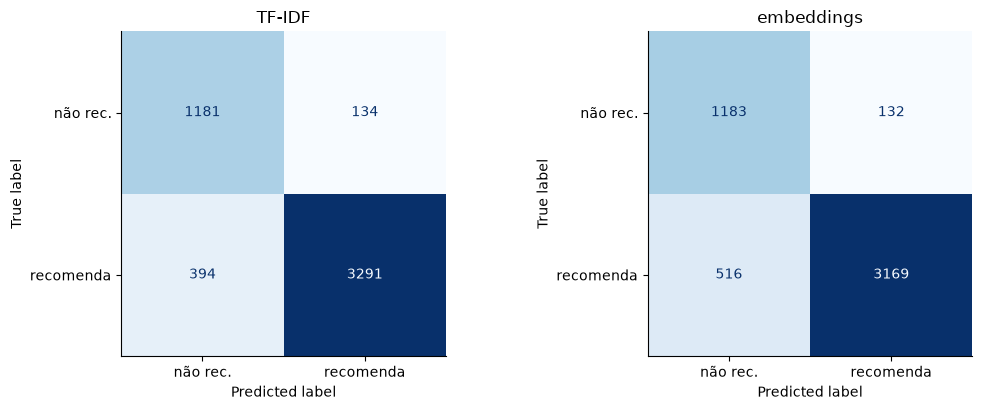

In [13]:
# Matriz de confusão: linhas = classe real, colunas = classe prevista. Fora da diagonal estão os erros.

from sklearn.metrics import ConfusionMatrixDisplay
fig, ax = plt.subplots(1, 2, figsize=(11, 4.2))
for a, (nome, p) in zip(ax, resultados.items()):
    ConfusionMatrixDisplay(confusion_matrix(y_te, p), display_labels=["não rec.", "recomenda"]).plot(ax=a, colorbar=False, cmap="Blues")
    a.set_title(nome)
plt.tight_layout(); plt.show()

### Solução: mover o limiar
A Regressão Logística devolve uma probabilidade. O limiar padrão é 0,5, mas a loja pode preferir pegar mais insatisfeitos, aceitando mais alarmes falsos.

In [14]:
# predict_proba(...)[:, 0] = probabilidade de "não recomenda". O predict usa limiar 0,5.
# 1 - y_te inverte os rótulos para medir "não recomenda" como classe positiva.
# Limiar baixo: mais insatisfeitos encontrados e mais alarmes falsos. É decisão de negócio.

from sklearn.metrics import precision_score, recall_score
p_nao = lr_t.predict_proba(X_te)[:, 0]
linhas = []
for lim in [0.3, 0.4, 0.5, 0.6, 0.7]:
    pred_nao = (p_nao >= lim).astype(int)
    linhas.append({"limiar": lim, "precisão 'não rec.'": precision_score(1 - y_te, pred_nao), "recall 'não rec.'": recall_score(1 - y_te, pred_nao), "marcados": int(pred_nao.sum())})
pd.DataFrame(linhas).round(3)

,limiar,precisão 'não rec.',recall 'não rec.',marcados
0,0.3,0.598,0.951,2091
1,0.4,0.677,0.927,1801
2,0.5,0.750,0.898,1575
3,0.6,0.807,0.855,1393
4,0.7,0.856,0.766,1176


## Bloco 3 · Do que os clientes reclamam?

### Problema
Não existe rótulo de **assunto** da reclamação. Queremos descobrir os temas das avaliações negativas (notas 1 e 2) sem dizer ao modelo quais são.

### Conceito
- **Agrupamento** junta documentos próximos no espaço de embeddings.
- **K-Means** precisa do número de grupos K; o **silhouette** ajuda a escolher.
- **LDA** (modelagem de tópicos) trata cada avaliação como uma **mistura** de tópicos, e cada tópico como uma distribuição de palavras.

In [15]:
# K-Means nas avaliações negativas (notas 1 e 2), testando K de 3 a 10.
# Silhouette: de -1 a 1; quanto maior, mais separados os grupos. sample_size acelera a conta.

from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
neg = amostra.index[amostra["overall_rating"] <= 2].to_numpy()
En = E[neg]
print("avaliações negativas:", len(neg))
sil = {}
for k in range(3, 11):
    km = KMeans(n_clusters=k, n_init=10, random_state=42).fit(En)
    sil[k] = silhouette_score(En, km.labels_, metric="cosine", sample_size=3000, random_state=42)
pd.Series(sil, name="silhouette").round(4).to_frame().T

avaliações negativas: 5192


,3,4,5,6,7,8,9,10
silhouette,0.133,0.1356,0.0971,0.076,0.0776,0.0573,0.0642,0.062


**Para pensar:** o que os valores de silhouette dizem sobre a separação entre os grupos? Além da métrica, que critério ajudaria a escolher K?

No baseline seguimos com **K = 6** só para demonstrar o método. A escolha de K, com justificativa, é parte da Etapa 2.

In [16]:
# c-TF-IDF: os textos de cada grupo viram um documento só; o TF-IDF entre eles mostra os termos que distinguem cada grupo.
# max_df=0.67 descarta termos presentes em quase todos os grupos.

K = 6
km = KMeans(n_clusters=K, n_init=10, random_state=42).fit(En)
amostra.loc[neg, "tema"] = km.labels_

# termos que caracterizam cada grupo (c-TF-IDF simplificado: um documento por grupo)
# aqui a lista padrão serve: queremos o assunto, e max_df descarta termos presentes em quase todos os grupos
docs_grupo = amostra.loc[neg].groupby("tema")["review_text"].apply(lambda s: " ".join(s.str.lower()))
STOP_TEMAS = set(stopwords.words("portuguese")) | {"produto", "americanas"}
ctf = TfidfVectorizer(min_df=2, max_df=0.67, stop_words=list(STOP_TEMAS), ngram_range=(1, 2))
M = ctf.fit_transform(docs_grupo); V = np.array(ctf.get_feature_names_out())
resumo = []
for g in range(K):
    termos_g = ", ".join(V[np.argsort(-M[g].toarray()[0])[:8]])
    resumo.append({"grupo": g, "avaliações": int((km.labels_ == g).sum()), "termos": termos_g})
pd.DataFrame(resumo)

,grupo,avaliações,termos
0,0,815,"samsung, smart, computador, sony, aplicativos, memória, motorola, ouvido"
1,1,1049,"perfume, falsificado, plástico, cabelo, cheiro, achando, quantidade, anuncio"
2,2,996,"ainda recebi, americana, reembolso, pré venda, devolução dinheiro, pré, parceiros, péssimo atendimento"
3,3,1047,"ainda recebi, previsão entrega, ainda entregue, agora recebi, entrega dia, ainda nao, dias úteis, status"
4,4,1043,"cabelo, tecido, colchão, madeira, base, parafusos, fundo, plástico"
5,5,242,"recebi recebi, ainda recebi, nao chegou, entrega cancelada, cancelada, compre nao, chegou nao, 09"


In [17]:
# As 3 avaliações mais próximas do centro de cada grupo (similaridade de cosseno).
# Os termos sugerem o tema; só a leitura confirma.

for g in range(K):
    centro = km.cluster_centers_[g] / np.linalg.norm(km.cluster_centers_[g])
    membros = neg[km.labels_ == g]
    perto = membros[np.argsort(-(E[membros] @ centro))[:3]]
    print(f"\n=== grupo {g}")
    for i in perto: print("  -", amostra.review_text[i][:130])


=== grupo 0
  - O aparelho trava, câmera é boa mas a cor que é proporcionada achei averlhada. E possui muitos problemas, como ligar e desligar soz
  - Este produto veio com defeito no interruptor...não desliga...tem que tirar o cabo da tomada.
  - recebi o produto com defeito, o mesmo não ativa o Wi-Fi. Pedi devolução, estou aguardando.

=== grupo 1
  - O produto veio com a régua de corte torto  As linhas da tábua tortas. Não irei fazer o trâmite de troca por que já estou bastante 
  - Recebi o produto errado e fizeram a troca.  Recebi ontem o novo produto e percebi que que existiam avarias como se o produto estiv
  - O produto veio solto dentro da caixa, apresentando marcas de uso e com defeito. Estou até hoje tentando devolução mas até agora na

=== grupo 2
  - Paguei e não levei. Vou processar as lojas americanas Até hoje não recebi o produto
  - Comprei e até hoje não me enviaram o produto, muita sacanagem um furto , estão nem aí com cliente
  - ate hoje não entregaram...pior que 

### LDA: tópicos como mistura

O K-Means coloca cada avaliação em **um** grupo. A **modelagem de tópicos** com **LDA** (*Latent Dirichlet Allocation*) parte de outra ideia:

- cada **tópico** é uma distribuição de probabilidade sobre as palavras do vocabulário;
- cada **avaliação** é uma **mistura** de tópicos, com pesos que somam 1.

O LDA trabalha com **contagens de palavras** (Bag-of-Words), não com TF-IDF nem com embeddings. Por isso o pré-processamento, e em especial a lista de stopwords, pesa muito no resultado.

In [18]:
# O LDA usa contagens (Bag-of-Words), não TF-IDF nem embeddings.
# min_df/max_df cortam palavras raras e onipresentes; token_pattern aceita só palavras com 3 letras ou mais.
# components_: peso de cada palavra em cada tópico. transform(C) = theta: a mistura de tópicos de cada avaliação.

from sklearn.feature_extraction.text import CountVectorizer
from sklearn.decomposition import LatentDirichletAllocation

textos_neg = amostra.loc[neg, "review_text"].map(normalizar)
STOP_LDA = list(STOP_TEMAS | {"compra", "comprei", "comprar", "dia", "dias", "pra", "vou", "veio"})
cv = CountVectorizer(min_df=5, max_df=0.5, stop_words=STOP_LDA, token_pattern=r"(?u)\b[^\W\d_]{3,}\b")
C = cv.fit_transform(textos_neg); vocab_lda = np.array(cv.get_feature_names_out())
print("matriz de contagens:", C.shape)

lda = LatentDirichletAllocation(n_components=K, learning_method="batch", max_iter=50, random_state=42).fit(C)
theta = lda.transform(C)
pd.DataFrame([{"tópico": k, "avaliações em que domina": int((theta.argmax(1) == k).sum()),
               "palavras": ", ".join(vocab_lda[np.argsort(-lda.components_[k])[:10]])} for k in range(K)])

matriz de contagens: (5192, 2268)


,tópico,avaliações em que domina,palavras
0,0,1173,"qualidade, ruim, recomendo, bem, péssima, achei, gostei, material, original, boa"
1,1,666,"pois, bem, porém, descrição, cor, diz, foto, anúncio, água, outra"
2,2,830,"aparelho, celular, uso, funciona, bateria, tela, problema, meses, menos, assistência"
3,3,564,"troca, defeito, contato, devolução, recebi, resposta, nada, pedi, agora, solicitei"
4,4,1241,"entrega, site, loja, recebi, prazo, entregue, empresa, pedido, agora, pois"
5,5,718,"recebi, ainda, avaliar, chegou, posso, entrega, mês, hoje, pois, agora"


In [19]:
# Segundo maior peso acima de 0,3: a avaliação tem pelo menos dois tópicos relevantes.

mistas = np.sort(theta, 1)[:, -2] > 0.3
print(f"avaliações com dois tópicos acima de 0,3: {mistas.sum()} ({mistas.mean():.0%})")
for i in np.where(mistas)[0][:3]:
    print("\n-", amostra.review_text[neg[i]][:200])
    print("  pesos por tópico:", np.round(theta[i], 2))

avaliações com dois tópicos acima de 0,3: 1697 (33%)

- Não indico a compra deste produto, o relógio não veio com a mesma cor da descrição e sem a caixa também. O vendedor não é confiável.
  pesos por tópico: [0.02 0.44 0.02 0.02 0.49 0.02]

- ate hoje não recebi. pedi explicação pela demora no site, por 2 vezes e não me responderam.
  pesos por tópico: [0.02 0.02 0.02 0.38 0.24 0.33]

- comprei o produto em novembro e já estamos em janeiro; ja expirou o prazo de entrega, e estou sem meu produto. e não me deram nenhuma satisfação até agora! Estou decepcionada com esta compra.ja até pa
  pesos por tópico: [0.01 0.01 0.01 0.01 0.32 0.64]


In [20]:
# Grupos do K-Means (linhas) × tópico dominante do LDA (colunas).
# Linha concentrada numa coluna: os métodos concordam. Linha espalhada: divergem.

pd.crosstab(km.labels_, theta.argmax(1), rownames=["grupo K-Means"], colnames=["tópico LDA dominante"])

tópico LDA dominante,0,1,2,3,4,5
grupo K-Means,,,,,,
0,163,67,452,78,40,15
1,386,227,112,103,135,86
2,62,53,59,157,551,114
3,10,21,45,140,419,412
4,507,275,140,54,29,38
5,45,23,22,32,67,53


### Mapa de tópicos com pyLDAvis

O **pyLDAvis** desenha o LDA de forma interativa:

- **À esquerda, o mapa de distância entre tópicos.** Cada círculo é um tópico, e a área é a fatia das palavras do corpus que ele ocupa. A distância entre círculos indica quão diferentes são os vocabulários: o pyLDAvis mede a divergência de Jensen-Shannon entre as distribuições de palavras e projeta essas distâncias em duas dimensões.
- **À direita, as barras.** Mostram as 30 palavras mais relevantes do tópico selecionado: em azul, a frequência da palavra no corpus inteiro; em vermelho, a frequência estimada dentro do tópico.
- **O controle λ (lambda)** muda o critério de relevância. Com λ = 1, as palavras mais prováveis no tópico, inclusive as genéricas. Com λ perto de 0, as mais exclusivas do tópico. Os autores sugerem começar em λ ≈ 0,6.

Clique num círculo para ver as barras daquele tópico. **Atenção à numeração:** o pyLDAvis numera os tópicos de 1 a K; `lda.components_` e `theta` vão de 0 a K−1.

In [21]:
# Mapa interativo do LDA: clique num círculo para ver as palavras do tópico.
# np.real(js_PCoA(...)) contorna um erro do pyLDAvis com versões recentes do NumPy.
# sort_topics=False mantém a ordem do modelo: tópico 1 do mapa = tópico 0 da tabela.

import importlib.util, subprocess, sys
if importlib.util.find_spec("pyLDAvis") is None:
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "pyLDAvis"], check=True)
import pyLDAvis, pyLDAvis.lda_model
from pyLDAvis._prepare import js_PCoA
pyLDAvis.enable_notebook()

def mapa_lda(modelo):
    return pyLDAvis.lda_model.prepare(modelo, C, cv, mds=lambda d: np.real(js_PCoA(d)), sort_topics=False)

mapa_lda(lda)

PreparedData(topic_coordinates=              x         y  topics  cluster       Freq
topic                                                
0      0.223678 -0.056212       1        1  18.483078
1      0.157269 -0.145335       2        1  14.396374
2      0.131038  0.177454       3        1  17.094008
3     -0.118980  0.144371       4        1  12.202011
4     -0.157507  0.013193       5        1  26.545266
5     -0.235498 -0.133470       6        1  11.279264, topic_info=            Term        Freq       Total Category  logprob  loglift
1791      recebi  982.000000  982.000000  Default  30.0000  30.0000
61         ainda  737.000000  737.000000  Default  29.0000  29.0000
1733   qualidade  440.000000  440.000000  Default  28.0000  28.0000
210      avaliar  331.000000  331.000000  Default  27.0000  27.0000
778      entrega  632.000000  632.000000  Default  26.0000  26.0000
...          ...         ...         ...      ...      ...      ...
257          bom   45.522066  272.133871   Topic6  -5.1111   0.3941
592       demora   37.660354  116.217853   Topic6  -5.3007   1.0553
1853    resposta   39.563904  180.920436   Topic6  -5.2514   0.6621
55    aguardando   37.761355  143.634115   Topic6  -5.2980   0.8462
1513      pedido   38.728307  235.716397   Topic6  -5.2727   0.3761

[415 rows x 6 columns], token_table=      Topic      Freq        Term
term                             
12        1  0.897946  acabamento
12        2  0.086104  acabamento
25        1  0.870608       achei
25        2  0.033744       achei
25        6  0.094485       achei
...     ...       ...         ...
2253      3  0.974490     youtube
2255      1  0.127345        água
2255      2  0.764067        água
2255      3  0.107753        água
2257      3  0.979624       áudio

[683 rows x 3 columns], R=30, lambda_step=0.01, plot_opts={'xlab': 'PC1', 'ylab': 'PC2'}, topic_order=[1, 2, 3, 4, 5, 6])

### Quantos tópicos? Comparando o mapa para vários K

Aumentar K divide tópicos. Enquanto os círculos novos ficam **separados**, a divisão separou vocabulários diferentes. Quando os círculos começam a **se sobrepor**, os tópicos passam a dividir palavras: pode ser sinal de que K passou do ponto, ou de que dois tópicos merecem ser juntados.

O mapa é uma projeção em 2D e depende da semente e das stopwords. Usem como **um critério entre outros**: leitura das palavras, leitura de exemplos e utilidade para a diretoria.

In [22]:
# Um LDA para cada K, com os mesmos parâmetros. Leva cerca de um minuto.

from IPython.display import display, Markdown
for K_lda in [3, 4, 5, 6]:
    lda_k = LatentDirichletAllocation(n_components=K_lda, learning_method="batch", max_iter=50, random_state=42).fit(C)
    display(Markdown(f"#### LDA com K = {K_lda}"))
    display(mapa_lda(lda_k))

#### LDA com K = 3

PreparedData(topic_coordinates=             x         y  topics  cluster       Freq
topic                                               
0      0.20877 -0.109996       1        1  34.284556
1     -0.22519 -0.087569       2        1  37.543712
2      0.01642  0.197565       3        1  28.171732, topic_info=           Term        Freq       Total Category  logprob  loglift
1791     recebi  982.000000  982.000000  Default  30.0000  30.0000
61        ainda  739.000000  739.000000  Default  29.0000  29.0000
778     entrega  633.000000  633.000000  Default  28.0000  28.0000
1733  qualidade  443.000000  443.000000  Default  27.0000  27.0000
578     defeito  301.000000  301.000000  Default  26.0000  26.0000
...         ...         ...         ...      ...      ...      ...
53        agora  124.018554  412.698319   Topic3  -5.0242   0.0646
1373       nada  115.308981  452.907559   Topic3  -5.0970  -0.1012
1806  recomendo  113.733625  453.170923   Topic3  -5.1108  -0.1156
504     contato   89.906150  284.869117   Topic3  -5.3459   0.1136
1601       pois   89.637622  555.446684   Topic3  -5.3489  -0.5571

[178 rows x 6 columns], token_table=      Topic      Freq        Term
term                             
4         2  0.019696        abri
4         3  0.984784        abri
8         2  0.985239     absurdo
12        1  0.990960  acabamento
25        1  0.891956       achei
...     ...       ...         ...
2209      3  0.554795         vez
2210      1  0.151783       vezes
2210      3  0.845651       vezes
2234      3  0.994088       volta
2255      1  0.990382        água

[213 rows x 3 columns], R=30, lambda_step=0.01, plot_opts={'xlab': 'PC1', 'ylab': 'PC2'}, topic_order=[1, 2, 3])

#### LDA com K = 4

PreparedData(topic_coordinates=              x         y  topics  cluster       Freq
topic                                                
0     -0.203211 -0.019062       1        1  24.047112
1      0.017688 -0.215922       2        1  17.986256
2     -0.073189  0.183330       3        1  21.455195
3      0.258712  0.051653       4        1  36.511437, topic_info=           Term        Freq       Total Category  logprob  loglift
1791     recebi  974.000000  974.000000  Default  30.0000  30.0000
1733  qualidade  443.000000  443.000000  Default  29.0000  29.0000
61        ainda  734.000000  734.000000  Default  28.0000  28.0000
778     entrega  628.000000  628.000000  Default  27.0000  27.0000
125    aparelho  251.000000  251.000000  Default  26.0000  26.0000
...         ...         ...         ...      ...      ...      ...
1411      nunca  167.778080  234.051834   Topic4  -4.9813   0.6746
896       falta  130.875381  151.654674   Topic4  -5.2297   0.8602
1601       pois  213.478721  557.344020   Topic4  -4.7404   0.0479
2114      troca  152.228003  270.411837   Topic4  -5.0786   0.4330
1678   problema  135.796644  287.166865   Topic4  -5.1928   0.2586

[256 rows x 6 columns], token_table=      Topic      Freq        Term
term                             
12        1  0.990973  acabamento
25        1  0.906231       achei
25        4  0.087267       achei
28        2  0.994593       acima
53        2  0.031766       agora
...     ...       ...         ...
2210      3  0.623911       vezes
2210      4  0.253917       vezes
2217      2  0.981273      vieram
2255      1  0.930037        água
2255      3  0.059364        água

[346 rows x 3 columns], R=30, lambda_step=0.01, plot_opts={'xlab': 'PC1', 'ylab': 'PC2'}, topic_order=[1, 2, 3, 4])

#### LDA com K = 5

PreparedData(topic_coordinates=              x         y  topics  cluster       Freq
topic                                                
0     -0.189100 -0.014015       1        1  19.878619
1     -0.122484  0.197398       2        1  15.175386
2     -0.091569 -0.194196       3        1  17.280528
3      0.188038 -0.052420       4        1  15.316017
4      0.215116  0.063234       5        1  32.349451, topic_info=           Term        Freq       Total Category  logprob  loglift
1791     recebi  972.000000  972.000000  Default  30.0000  30.0000
1733  qualidade  442.000000  442.000000  Default  29.0000  29.0000
778     entrega  625.000000  625.000000  Default  28.0000  28.0000
2114      troca  274.000000  274.000000  Default  27.0000  27.0000
578     defeito  302.000000  302.000000  Default  26.0000  26.0000
...         ...         ...         ...      ...      ...      ...
957         fiz  132.489990  206.042145   Topic5  -5.0964   0.6870
675    dinheiro  132.275108  272.801214   Topic5  -5.0980   0.4047
2165      valor  103.645006  148.506525   Topic5  -5.3419   0.7689
1806  recomendo  124.350513  451.432761   Topic5  -5.1598  -0.1607
2047        ter  115.449560  327.660327   Topic5  -5.2341   0.0854

[342 rows x 6 columns], token_table=      Topic      Freq        Term
term                             
12        1  0.993203  acabamento
25        1  0.967734       achei
25        4  0.026882       achei
28        2  0.975854       acima
35        4  0.960208    acontece
...     ...       ...         ...
2210      5  0.144544       vezes
2217      2  0.983721      vieram
2253      3  0.968964     youtube
2255      2  0.989057        água
2257      3  0.974053       áudio

[538 rows x 3 columns], R=30, lambda_step=0.01, plot_opts={'xlab': 'PC1', 'ylab': 'PC2'}, topic_order=[1, 2, 3, 4, 5])

#### LDA com K = 6

PreparedData(topic_coordinates=              x         y  topics  cluster       Freq
topic                                                
0      0.223678 -0.056212       1        1  18.483078
1      0.157269 -0.145335       2        1  14.396374
2      0.131038  0.177454       3        1  17.094008
3     -0.118980  0.144371       4        1  12.202011
4     -0.157507  0.013193       5        1  26.545266
5     -0.235498 -0.133470       6        1  11.279264, topic_info=            Term        Freq       Total Category  logprob  loglift
1791      recebi  982.000000  982.000000  Default  30.0000  30.0000
61         ainda  737.000000  737.000000  Default  29.0000  29.0000
1733   qualidade  440.000000  440.000000  Default  28.0000  28.0000
210      avaliar  331.000000  331.000000  Default  27.0000  27.0000
778      entrega  632.000000  632.000000  Default  26.0000  26.0000
...          ...         ...         ...      ...      ...      ...
257          bom   45.522066  272.133871   Topic6  -5.1111   0.3941
592       demora   37.660354  116.217853   Topic6  -5.3007   1.0553
1853    resposta   39.563904  180.920436   Topic6  -5.2514   0.6621
55    aguardando   37.761355  143.634115   Topic6  -5.2980   0.8462
1513      pedido   38.728307  235.716397   Topic6  -5.2727   0.3761

[415 rows x 6 columns], token_table=      Topic      Freq        Term
term                             
12        1  0.897946  acabamento
12        2  0.086104  acabamento
25        1  0.870608       achei
25        2  0.033744       achei
25        6  0.094485       achei
...     ...       ...         ...
2253      3  0.974490     youtube
2255      1  0.127345        água
2255      2  0.764067        água
2255      3  0.107753        água
2257      3  0.979624       áudio

[683 rows x 3 columns], R=30, lambda_step=0.01, plot_opts={'xlab': 'PC1', 'ylab': 'PC2'}, topic_order=[1, 2, 3, 4, 5, 6])

**Para pensar:** em que K os círculos começam a se sobrepor? Que tópico se divide quando K passa de 3 para 4? As palavras dos tópicos sobrepostos são parecidas?

**Para pensar:** que nome cada tópico merece? Os tópicos do LDA coincidem com os grupos do K-Means? O que um método mostra que o outro não mostra? Leiam exemplos antes de responder.

### Nomeando os tópicos e vendo como as avaliações se distribuem

Depois de ler as palavras e os exemplos, deem um **nome curto** a cada tópico no formulário (no Colab, os campos aparecem ao lado do código). Os nomes começam genéricos: a escolha é de vocês. As células seguintes usam esses nomes para mostrar **quantas avaliações** caem em cada tópico, **quão separados** eles ficam e **quais avaliações** melhor representam cada um.

In [ ]:
#@title Nomes dos tópicos do LDA
# Um nome por tópico, na ordem da tabela do LDA (tópico 0, 1, 2...). Rodem de novo sempre que mudarem um nome.
# Se o LDA tiver mais de 6 tópicos, os excedentes ficam com o nome genérico.

nome_0 = "Tópico 0"  #@param {type:"string"}
nome_1 = "Tópico 1"  #@param {type:"string"}
nome_2 = "Tópico 2"  #@param {type:"string"}
nome_3 = "Tópico 3"  #@param {type:"string"}
nome_4 = "Tópico 4"  #@param {type:"string"}
nome_5 = "Tópico 5"  #@param {type:"string"}

K_lda = lda.n_components
nomes_topicos = ([nome_0, nome_1, nome_2, nome_3, nome_4, nome_5] + [f"Tópico {k}" for k in range(6, K_lda)])[:K_lda]
dom = theta.argmax(1)                      # tópico dominante de cada avaliação
amostra.loc[neg, "topico_lda"] = np.array(nomes_topicos)[dom]
pd.DataFrame({"nome": nomes_topicos,
              "palavras": [", ".join(vocab_lda[np.argsort(-lda.components_[k])[:8]]) for k in range(K_lda)]}).rename_axis("tópico")

,nome,palavras
tópico,,
0,Tópico 0,"qualidade, ruim, recomendo, bem, péssima, achei, gostei, material"
1,Tópico 1,"pois, bem, porém, descrição, cor, diz, foto, anúncio"
2,Tópico 2,"aparelho, celular, uso, funciona, bateria, tela, problema, meses"
3,Tópico 3,"troca, defeito, contato, devolução, recebi, resposta, nada, pedi"
4,Tópico 4,"entrega, site, loja, recebi, prazo, entregue, empresa, pedido"
5,Tópico 5,"recebi, ainda, avaliar, chegou, posso, entrega, mês, hoje"


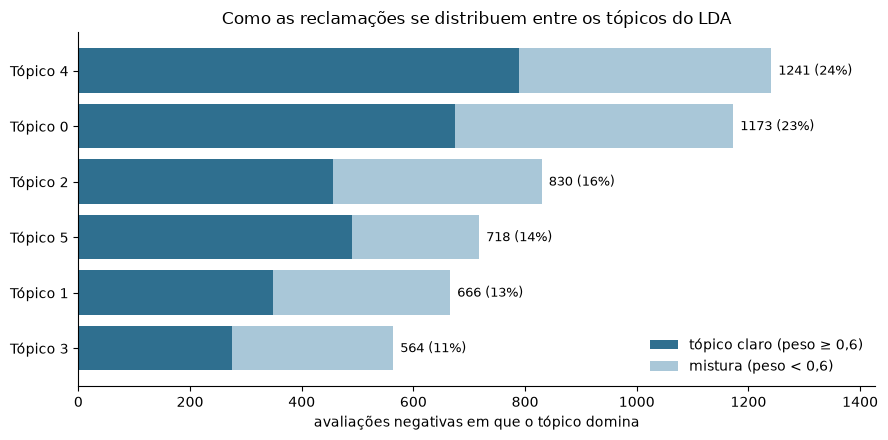

58% das avaliações têm um tópico claro; 42% são mistura.


,avaliações,"claro (≥ 0,6)",mistura,peso médio,% das avaliações
nome,,,,,
Tópico 4,1241,790,451,0.218,0.239
Tópico 0,1173,675,498,0.207,0.226
Tópico 2,830,456,374,0.157,0.160
Tópico 5,718,490,228,0.151,0.138
Tópico 1,666,349,317,0.141,0.128
Tópico 3,564,276,288,0.126,0.109


In [ ]:
# Distribuição: em quantas avaliações cada tópico domina e com que folga.
# "claro": o tópico dominante tem peso de 0,6 ou mais; "mistura": domina por pouco, a avaliação fala de mais de um assunto.
# peso médio = theta.mean(0): a fatia de cada tópico em todo o conjunto, contando também as misturas.

claro = theta.max(1) >= 0.6
dist = pd.DataFrame({"nome": nomes_topicos,
                     "avaliações": np.bincount(dom, minlength=K_lda),
                     "claro (≥ 0,6)": np.bincount(dom[claro], minlength=K_lda),
                     "mistura": np.bincount(dom[~claro], minlength=K_lda),
                     "peso médio": theta.mean(0)})
dist["% das avaliações"] = dist["avaliações"] / len(dom)
dist = dist.sort_values("avaliações")

fig, ax = plt.subplots(figsize=(9, 0.55 * K_lda + 1.2))
ax.barh(dist["nome"], dist["claro (≥ 0,6)"], color="#2F6F8F", label="tópico claro (peso ≥ 0,6)")
ax.barh(dist["nome"], dist["mistura"], left=dist["claro (≥ 0,6)"], color="#A9C7D8", label="mistura (peso < 0,6)")
for i, (n, pct) in enumerate(zip(dist["avaliações"], dist["% das avaliações"])):
    ax.text(n + dist["avaliações"].max() * 0.01, i, f"{n} ({pct:.0%})", va="center", fontsize=9)
ax.set_xlabel("avaliações negativas em que o tópico domina")
ax.set_title("Como as reclamações se distribuem entre os tópicos do LDA")
ax.legend(loc="lower right", frameon=False); ax.set_xlim(0, dist["avaliações"].max() * 1.15)
plt.tight_layout(); plt.show()

print(f"{claro.mean():.0%} das avaliações têm um tópico claro; {(~claro).mean():.0%} são mistura.")
dist.sort_values("avaliações", ascending=False).set_index("nome").round(3)

In [ ]:
# Mapa das avaliações negativas no espaço dos embeddings (UMAP), colorido pelo tópico dominante do LDA.
# O LDA não viu os embeddings: ele usa contagens de palavras. Se uma cor forma uma região, os dois olhares concordam.
# Menu: trocar a cor para o grupo do K-Means e comparar. Passem o mouse sobre um ponto para ler a avaliação.
import umap, html, textwrap, plotly.graph_objects as go, plotly.express as px

xy_neg = umap.UMAP(n_neighbors=15, min_dist=0.1, metric="cosine", random_state=42).fit_transform(En)
grupo_km = np.array([f"grupo {g}" for g in km.labels_])
frases_neg = np.array(["<br>".join(textwrap.wrap(html.escape(t[:280]), 70))
                       + f"<br><b>{nomes_topicos[d]} (peso {theta[i, d]:.2f}) · K-Means: {grupo_km[i]}</b>"
                       for i, (t, d) in enumerate(zip(amostra.loc[neg, "review_text"].values, dom))])

PALETA = px.colors.qualitative.Bold + px.colors.qualitative.Pastel
modos = {"tópico do LDA": (np.array(nomes_topicos)[dom], list(dict.fromkeys(nomes_topicos))),
         "grupo do K-Means": (grupo_km, [f"grupo {g}" for g in range(km.n_clusters)])}
fig = go.Figure(); botoes = []; total = sum(len(c) for _, c in modos.values()); k = 0
for m, (nome, (valores, cats)) in enumerate(modos.items()):
    for c, cat in enumerate(cats):
        sel = valores == cat
        fig.add_trace(go.Scattergl(x=xy_neg[sel, 0], y=xy_neg[sel, 1], mode="markers", name=f"{cat} ({sel.sum()})",
                                   visible=(m == 0), marker=dict(size=5, color=PALETA[c % len(PALETA)], opacity=0.75),
                                   text=frases_neg[sel], hovertemplate="%{text}<extra></extra>"))
    vis = [False] * total; vis[k:k + len(cats)] = [True] * len(cats); k += len(cats)
    botoes.append(dict(label=nome, method="update", args=[{"visible": vis}]))
fig.update_layout(title="Avaliações negativas no espaço dos embeddings (UMAP)", height=620, template="plotly_white",
                  updatemenus=[dict(buttons=botoes, x=0, y=1.1, xanchor="left")],
                  xaxis=dict(visible=False), yaxis=dict(visible=False), legend=dict(itemsizing="constant"))
fig.show()

In [ ]:
# As 3 avaliações em que cada tópico tem o maior peso: confiram se o nome escolhido combina com elas.

for k, nome in enumerate(nomes_topicos):
    print(f"\n■ {nome} (tópico {k}) · domina em {(dom == k).sum()} avaliações")
    for i in np.argsort(-theta[:, k])[:3]:
        print(f"  [{theta[i, k]:.2f}] {amostra.review_text[neg[i]][:200]}")


■ Tópico 0 (tópico 0) · domina em 1173 avaliações
  [0.97] Gostei pouco. O produto faz o que promete, porém com qualidade muito baixa na resolução em real time e luminosidade muito fraca, é necessário ter uma lampada extra para iluminar o ambiente. Outro pont
  [0.96] Boa aparência, porem acabamento muito ruim ,  as quinas muito afiada  acho que deveria ser mais bem acabada pois pode até se cortar nas quinas . Algumas partes descascadas.  se caso fosse comprar nova
  [0.96] Ela só é ruim pra usar como smart,eu não sabia que iria precisar de fio para conectar internet. Más se for usada apenas no modo tv ela é boa... ah os parafusos do pezinho da tv é diferente, vem um gra

■ Tópico 1 (tópico 1) · domina em 666 avaliações
  [0.99] Produto apesar de bem construído, tem sérios defeitos nas funcionalidades.  - Tem base aquecida (para que??????). A jarra é de inox, não faz diferença alguma a base aquecida. só gasta energia. Inclusi
  [0.97] Na descrição do produto esta " Altura colchão: 22,

**Para pensar:** os tópicos estão equilibrados ou um deles concentra a maior parte das reclamações? Que tópicos têm mais mistura, e com quais outros eles se misturam? No mapa, cada nome forma uma região ou as cores se espalham? E com as cores do K-Means? Depois de ler os exemplos, o nome que vocês deram ainda faz sentido?

## Bloco 4 · Onde o modelo erra

### Problema
Um F1 de 0,8 não diz **por que** os outros 20% erram.

### Conceito: análise estruturada de erro
Ler os erros e classificá-los em categorias, contar e agir na mais frequente. Categorias úteis aqui: **rótulo contraditório** (nota 5 e "não recomenda"), **ironia**, **reclamação da loja, produto bom**, **texto curto ou genérico**, **erro real do modelo**.

In [23]:
# Erros do classificador: avaliações do teste em que previsão e rótulo real discordam.

p = resultados["TF-IDF"]
erros = amostra.iloc[idx_te][p != y_te][["overall_rating", "recommend_to_a_friend", "review_text"]].copy()
erros["previsto"] = np.where(p[p != y_te] == 1, "Yes", "No")
print("erros no teste:", len(erros))
erros.sample(10, random_state=1)

erros no teste: 528


,overall_rating,recommend_to_a_friend,review_text,previsto
15950,1,No,Comprem uma sem esse formato no meio! Cabe pouquissimo cabelo e é todo complicado! Até a chapinha é mais pratico,Yes
963,3,No,"Bom, mas acho que a garantia deixou a desejar. O fabricante geralmente oferece 1 ano de garantia e aqui só encontrei 3 meses. O mesmo pr...",Yes
6238,4,Yes,"Muito funciona tranquilo sem muito segredo , conectou, pareou ele pronto....",No
530,5,Yes,"O aparelho é muito bom! Tem uma câmara excelente, tanto a traseira como a frontal. Eu já tirei várias fotos e gravei vários vídeos, e ai...",No
4363,3,No,"Comprei especificamente para me barbear , mas com lâmina fica melhor pois a barba não fica rente a pele, para aparar cabelo e barba até ...",Yes
15909,2,Yes,produto bom mas veio com defeito preciso trocar urgente como proceder,No
19454,4,Yes,"As especificações do produto estão escritas de uma forma absurdamente incorreta. O site deveria, no mínimo, fazer a correção ortográfica.",No
18848,2,Yes,"Achei o produto bom, e parece ser resistente, porém tive um problema com a montagem, o encosto de costas veio torto, de modo que impossi...",No
9580,3,Yes,"O produto é bom, mas a loja não é séria! Enviaram um cor diferente da solicitada!",No
2240,1,No,"Sinceramente, a maior burrice alguém comprar esse computador por esse preço, com esse valor da pra comprar uma configuração muito melhor.",Yes


In [24]:
# Nota alta sem recomendar, ou nota baixa recomendando. & = "e", | = "ou"; cada condição entre parênteses.

# Rótulos contraditórios: a nota e a recomendação discordam
contra = amostra[((amostra.overall_rating >= 4) & (amostra.recomenda == 0)) | ((amostra.overall_rating <= 2) & (amostra.recomenda == 1))]
print(f"avaliações com nota e recomendação contraditórias: {len(contra)} ({len(contra)/len(amostra):.1%})")
contra[["overall_rating", "recommend_to_a_friend", "review_text"]].head(6)

avaliações com nota e recomendação contraditórias: 613 (3.1%)


,overall_rating,recommend_to_a_friend,review_text
30,5,No,"Sinceramente estou bastante desapontado, confiei fiz a pré venda na loja e realmente não vale a pena... me desculpe mas nunca mas faç..."
67,4,No,Pagar esse preço numa TV e ter apenas míseros 12 meses de garantia? Tá de brincadeira! Quando o consumidor brasileiro vai deixar de se...
106,5,No,"Asus cada vez melhor, carrega muito mais rápido , não esquenta muito quando em uso , se não estiver usando app pesando a bateria dura m..."
212,1,Yes,"Gostei do produto, porém o site é muito desorganizado, mercadoria não chega no dia previsto, são colocadas informações que não são verda..."
310,2,Yes,Eu teria á oposição de troca ou devolução do produto mais meu cunhado não quis fazer o procedimento mais tudo bem espero que os outros d...
345,1,Yes,Não acompanha adaptador para Iphone. Logo.. propaganda enganosa.


**Para pensar:** quantas avaliações aparecem? O que isso significa para os erros do Bloco 1?

---
# Etapa 2 do projeto · entrega até 30/11, 23h59

Até aqui, o notebook mostrou o **baseline do professor** (20 mil avaliações, semente 42). A partir daqui, o trabalho é do grupo, sobre a **amostra do grupo** definida na Etapa 1.

O grupo faz **as duas tarefas**:
- **Classificar:** prever se o cliente recomendaria o produto (Blocos 1 e 2).
- **Agrupar:** descobrir os temas das avaliações negativas (notas 1 e 2) com **K-Means e LDA** (Bloco 3).

**Sugestão de divisão:** no laboratório, parte do grupo cuida do Item 2 e parte do Item 3; a análise de erro (Item 4) é feita em conjunto. Todos devem conseguir explicar as duas tarefas.

**Como entregar**
1. Salvem uma cópia deste notebook no repositório do grupo (*Arquivo › Salvar uma cópia no GitHub*).
2. Preencham cada item: as células de código têm comentários com o que fazer; as células **Resposta do grupo** são para o texto.
3. Rodem o notebook inteiro antes de entregar, para que as saídas fiquem salvas.
4. Atualizem o README do repositório com um resumo dos resultados.

| # | Item | Critério de aceite | Pontos |
|---|---|---|---|
| 1 | Amostra | A amostra do grupo (mesma semente da Etapa 1) e as representações recarregadas | 1 |
| 2 | Classificação | TF-IDF e embeddings na mesma divisão; métricas por classe, matriz de confusão e baseline; limiar justificado | 3 |
| 3 | Agrupamento | K-Means e LDA com K justificado; temas nomeados com termos, exemplos e loja × produto; comparação dos dois métodos | 3 |
| 4 | Análise de erro | 5 erros do classificador e 5 avaliações mal agrupadas, categorizados e contados, com uma ação para a categoria mais frequente | 3 |
| 5 | Individual | Cada integrante: 3 erros, com uma ação concreta para cada | 5 |

Itens 1 a 4: grupo (10 pontos). Item 5: individual (5 pontos).

## Item 1 · Amostra

**O que fazer:** voltar à amostra do grupo e às representações da Etapa 1.

- Recriem a amostra com a **mesma semente, tamanho e critério** da Etapa 1. Ela substitui a variável `amostra` do baseline.
- Criem a coluna `recomenda` (seção 0 deste notebook).
- Recarreguem os embeddings salvos na Etapa 1 (`np.load`) ou recalculem.
- Separem as avaliações negativas (notas 1 e 2) para o agrupamento.

**Critério de aceite:** a amostra do grupo (mesma semente da Etapa 1) e as representações recarregadas.

In [25]:
# Item 1 · Amostra do grupo (a mesma da Etapa 1)
#   SEMENTE = <a semente do grupo na Etapa 1>
#   amostra = df.sample(<tamanho da Etapa 1>, random_state=SEMENTE).reset_index(drop=True)     # ou o critério estratificado usado
#   amostra = amostra[amostra["recommend_to_a_friend"].isin(["Yes", "No"])].reset_index(drop=True)
#   amostra["recomenda"] = (amostra["recommend_to_a_friend"] == "Yes").astype(int)
#
# Embeddings: carreguem o arquivo salvo na Etapa 1 (confiram se tem uma linha por avaliação) ou recalculem:
#   E = np.load("<caminho>/embeddings.npy")
#   assert len(E) == len(amostra), "os embeddings não correspondem à amostra"
#   # E = modelo.encode(amostra["review_text"].tolist(), batch_size=128, normalize_embeddings=True, show_progress_bar=True)
#
# Avaliações negativas, para o Item 3:
#   neg = amostra.index[amostra["overall_rating"] <= 2].to_numpy(); En = E[neg]
#   print("avaliações:", len(amostra), "| negativas:", len(neg))

**Resposta do grupo (Item 1):** confirmem a amostra (semente, tamanho e critério), quantas avaliações entram na classificação e quantas negativas entram no agrupamento. Digam também como o grupo dividiu o trabalho.

_Escrevam aqui._

## Item 2 · Classificação · quem não recomenda?

**2a · Modelos.** Separem treino e teste **uma vez** (estratificado) e usem a mesma divisão nas duas representações. Treinem a Regressão Logística com TF-IDF e com embeddings. O TF-IDF aprende **só com o treino** (Bloco 1).

**2b · Métricas.** Comparem o **baseline** ("sempre recomenda") e os dois modelos, com acurácia, F1 da classe "não recomenda" e F1 macro. Mostrem o `classification_report` e a **matriz de confusão** do melhor modelo (Blocos 1 e 2).

**2c · Limiar.** Testem vários limiares e escolham um. Justifiquem pelo **custo dos dois erros**: perder um insatisfeito ou acionar o atendimento para um satisfeito (Bloco 2).

**Critério de aceite:** TF-IDF e embeddings na mesma divisão; métricas por classe, matriz de confusão e baseline; limiar justificado.

In [26]:
# Item 2a · Modelos
# 1) Divisão treino/teste única, estratificada (Bloco 1):
#   idx_tr, idx_te = train_test_split(np.arange(len(amostra)), test_size=0.25, random_state=SEMENTE, stratify=amostra["recomenda"])
# 2) TF-IDF: fit só no treino, transform no teste.
# 3) Regressão Logística com TF-IDF e com embeddings (E[idx_tr], E[idx_te]), class_weight="balanced".
# 4) Mostrem o dataset (matriz TF-IDF de algumas avaliações), os maiores, menores e quase nulos pesos,
#    e a fórmula aplicada a uma avaliação (Bloco 1).
# 5) Opcional: o mapa interativo dos embeddings do teste (Bloco 1), com a amostra do grupo.


In [27]:
# Item 2b · Métricas
# Baseline (np.ones_like), tabela com as três métricas, classification_report e ConfusionMatrixDisplay (Blocos 1 e 2).

In [28]:
# Item 2c · Limiar: precisão, recall e quantos seriam marcados (Bloco 2)
#   p_nao = <modelo>.predict_proba(<X de teste>)[:, 0]
#   for lim in [0.3, 0.4, 0.5, 0.6, 0.7]: ...

**Resposta do grupo (Item 2):** qual representação venceu, por quanto, e por quê? O modelo supera o baseline em quê? Qual limiar o grupo escolheu, e qual custo pesou mais na decisão?

_Escrevam aqui._

## Item 3 · Agrupamento · do que reclamam?

**Amostra:** o agrupamento usa as avaliações negativas **da amostra do grupo** (Item 1), não as do baseline. Como cada grupo tem semente e tamanho próprios, cada grupo agrupa um conjunto diferente de reclamações.

**3a · K-Means** sobre os embeddings das avaliações negativas. Testem vários K com o silhouette, descrevam cada grupo pelos termos do c-TF-IDF e leiam **3 avaliações** próximas do centro (Bloco 3).

**3b · LDA** sobre as contagens das mesmas avaliações. Ajustem as stopwords, comparem os mapas do pyLDAvis para vários K e leiam as palavras e exemplos de cada tópico (Bloco 3).

**3c · Temas e comparação.** Deem um **nome** a cada tema e digam se ele é responsabilidade da **loja** (entrega, atendimento, reembolso) ou do **produto** (defeito, qualidade, anúncio). Comparem os dois métodos com uma tabela cruzada: o que um encontra que o outro não encontra?

**Justifiquem o K de cada método** com uma métrica ou o mapa de tópicos **e** um argumento de negócio: quantos temas a diretoria consegue acompanhar e agir?

**Critério de aceite:** K-Means e LDA com K justificado; temas nomeados com termos, exemplos e loja × produto; comparação dos dois métodos.

In [29]:
# Item 3a · K-Means (Bloco 3)
# 1) Silhouette para K de 3 a 10 sobre En (metric="cosine").
# 2) K-Means com o K escolhido; c-TF-IDF por grupo; 3 avaliações mais próximas de cada centro.

In [30]:
# Item 3b · LDA (Bloco 3)
# 1) CountVectorizer sobre os textos negativos, com a lista de stopwords do grupo:
#   C = CountVectorizer(min_df=5, max_df=0.5, stop_words=<lista do grupo>, token_pattern=r"(?u)\b[^\W\d_]{3,}\b").fit_transform(<textos negativos>)
# 2) Mapas do pyLDAvis para vários K (mapa_lda, Bloco 3); escolham K.
#   lda = LatentDirichletAllocation(n_components=<K>, learning_method="batch", max_iter=50, random_state=SEMENTE).fit(C)
# 3) Palavras de cada tópico, tópico dominante (theta.argmax(1)) e exemplos com maior peso em cada tópico.
# 4) Nomes dos tópicos e distribuição: formulário de nomes, gráfico de barras e mapa UMAP ("Nomeando os tópicos", Bloco 3).

In [31]:
# Item 3c · Comparação entre os dois métodos
#   pd.crosstab(<rótulos do K-Means>, theta.argmax(1), rownames=["grupo K-Means"], colnames=["tópico LDA dominante"])

**Resposta do grupo (Item 3):**

Qual K escolheram em cada método, e por quê?

_Escrevam aqui._

| Método | Grupo ou tópico | Nome do tema | Avaliações | Termos principais | Loja ou produto |
|---|---|---|---|---|---|
| K-Means |  |  |  |  |  |
| LDA |  |  |  |  |  |

O que os dois métodos têm em comum? O que um mostra que o outro não mostra?

_Escrevam aqui._

## Item 4 · Análise de erro

**O que fazer:**
1. Separem **5 erros do classificador** (avaliações do teste com previsão diferente do real) e **5 avaliações mal agrupadas** (que não combinam com o tema do grupo ou tópico em que caíram, no K-Means ou no LDA).
2. Deem uma **categoria** a cada uma: rótulo contraditório, reclamação da loja com produto bom, fora do escopo (pergunta, spam), ironia ou texto ambíguo, texto curto ou genérico, assunto novo, erro real do modelo.
3. **Contem** as categorias e proponham **uma ação** para a mais frequente.

**Critério de aceite:** 5 erros do classificador e 5 avaliações mal agrupadas, categorizados e contados, com uma ação para a categoria mais frequente.

In [32]:
# Item 4 · Separar e ler os erros
# Classificação (Bloco 4):
#   erros = amostra.iloc[idx_te][p != y_te][["overall_rating", "recommend_to_a_friend", "review_text"]]
#   erros.sample(5, random_state=SEMENTE)
# Agrupamento: 5 avaliações longe do centro do grupo (K-Means) ou com peso baixo no tópico dominante (LDA).
#
# Tabela da análise: uma linha por erro.
#   analise = pd.DataFrame([
#       {"tarefa": "classificação ou agrupamento", "texto": "...", "real ou esperado": "...", "previsto ou grupo": "...",
#        "categoria do erro": "...", "ação proposta": "..."},
#   ])
#   analise["categoria do erro"].value_counts()

**Resposta do grupo (Item 4):** qual categoria foi a mais frequente? Ela aparece nas duas tarefas? Qual ação o grupo propõe, e o que se espera que melhore?

_Escrevam aqui._

## Item 5 · Individual (5 pontos)

Cada integrante escolhe **3 erros** (da tabela do grupo ou outros, de qualquer uma das duas tarefas) e propõe, para cada um, uma **ação concreta**: o que mudar no dado, no pré-processamento, no modelo ou no processo, e por que isso resolveria aquele caso.

Grupos menores apagam as subseções que sobrarem.

**Critério de aceite:** 3 erros, com uma ação concreta para cada.

### Integrante 1 · _nome_

| Erro (texto resumido) | Tarefa | Categoria | Ação concreta | Por que resolve |
|---|---|---|---|---|
|  |  |  |  |  |
|  |  |  |  |  |
|  |  |  |  |  |

### Integrante 2 · _nome_

| Erro (texto resumido) | Tarefa | Categoria | Ação concreta | Por que resolve |
|---|---|---|---|---|
|  |  |  |  |  |
|  |  |  |  |  |
|  |  |  |  |  |

### Integrante 3 · _nome_

| Erro (texto resumido) | Tarefa | Categoria | Ação concreta | Por que resolve |
|---|---|---|---|---|
|  |  |  |  |  |
|  |  |  |  |  |
|  |  |  |  |  |

### Integrante 4 · _nome_

| Erro (texto resumido) | Tarefa | Categoria | Ação concreta | Por que resolve |
|---|---|---|---|---|
|  |  |  |  |  |
|  |  |  |  |  |
|  |  |  |  |  |